# Trabajo final Python para Ciencia de Datos
### Santiago Macedo, Dylan Gandaria

In [22]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
SEED = 42

## 1 - Introducción
Para el trabajo elegimos un conjunto de datos que contiene registros que exploran la relacion que existe entre las horas de sueño y de uso de pantallas con el rendimiento academico de estudiantes.
En este conjunto podremos ver informacion demografica, patrones de sueño, habitos de uso de pantallas, resultados academicos y de estilo de vida.
Este conjunto de datos esta construido para explorar especificamente el vinculo que existe entre el tiempo de sueño y el uso de pantallas con los resultados academicos, debido a que estos son considerados grandes factores de riesgo academico.
Es un conjunto de datos simulado artificialmente y no extraido de estudiantes reales, con el objetivo de que las horas de sueño, estudio y pantalla predigan de manera significativa los resultados academicos de los estudiantes. Contiene outliers introducidos de forma externa al algoritmo de simulacion utilizado. El proposito de este conjunto de datos es educacional y esta hecho para practicar, por lo que **no puede ser utilizado para extraer conclusiones sobre ningun fenomeno observado en el mundo real.**


In [23]:
df = pd.read_csv('../data/raw/data.csv')

## 2 - Datos
Este conjunto proviene de la plataforma Kaggle y se puede ver en el siguiente [link](https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance?resource=download)

El conjunto contiene 500 observaciones de estudiantes simulados.
| Variable | Tipo | Descripción |
|---|---|---|
| `student_id` | Identificador | Código único del estudiante |
| `age` | Numérica (discreta) | Edad en años (17 a 27). |
| `gender` | Categórica | Género: Female, Male, Non-binary, Prefer not to say. Presenta categorías duplicadas por escritura (`male`, `F`, `M`, etc.)  |
| `year_of_study` | Ordinal | Año de la carrera que cursa (1 a 5). |
| `major_category` | Categórica | Área de estudio: STEM, Business, Social Sciences, Health Sciences, Humanities, Arts, Law. |
| `residence_type` | Categórica | Tipo de vivienda: Dormitory, Off-campus Apartment, With Family, Homestay. |
| `chronotype` | Categórica | Cronotipo: Early Bird, Intermediate, Night Owl. |
| `avg_bedtime_hour` | Numérica (continua) | Hora promedio de acostarse, en formato 0 a 24 (por ejemplo, 23.1 = 23:06; 0.9 = 00:54). |
| `avg_sleep_hours_weekday` | Numérica (continua) | Horas promedio de sueño en días de semana. |
| `weekend_sleep_delta_hours` | Numérica (continua) | Diferencia en horas de sueño entre fin de semana y días de semana (valores positivos indican que duerme más el fin de semana). |
| `pre_sleep_screen_time_min` | Numérica (continua) | Minutos de uso de pantallas antes de dormir. |
| `daily_screen_time_hours` | Numérica (continua) | Horas diarias totales de uso de pantallas. |
| `primary_device` | Categórica | Dispositivo principal: Smartphone, Laptop, Tablet. |
| `device_free_before_bed` | Categórica (binaria) | Si evita dispositivos antes de dormir (Yes/No). |
| `caffeine_drinks_per_day` | Numérica (discreta) | Bebidas con cafeína por día. |
| `naps_per_week` | Numérica (discreta) | Siestas por semana (0 a 7). |
| `sleep_quality_score` | Ordinal | Calidad del sueño autopercibida (escala de 1 a 10). |
| `exercise_days_per_week` | Numérica (discreta) | Días de ejercicio por semana (0 a 7). |
| `energy_level` | Ordinal | Nivel de energía autopercibido (escala de 1 a 10). |
| `concentration_difficulty` | Ordinal | Dificultad de concentración autopercibida (escala de 1 a 10). |
| `weekly_study_hours` | Numérica (continua) | Horas de estudio por semana. |
| `class_attendance_percent` | Numérica (continua) | Porcentaje de asistencia a clase. |
| `has_part_time_job` | Categórica (binaria) | Si tiene trabajo de medio tiempo (Yes/No). |
| `semester_type` | Categórica | Semestre en que se registró: Fall, Spring, Summer. |
| `cgpa` | Numérica (continua) | Promedio acumulado de calificaciones (rango observado: 1.89 a 3.95). **Variable de interés.** |

### Aspectos relevantes del conjunto

- **Valores faltantes:** `energy_level` (15), `concentration_difficulty` (14), `device_free_before_bed` (9), `cgpa` (7) y `sleep_quality_score` (6).
- **Inconsistencias de formato:** la variable `gender` mezcla mayúsculas, minúsculas y abreviaturas.
- **Valores extremos:** se observan casos atípicos en horas de estudio, uso de pantalla y horas de sueño que fueron introducidos a proposito para simular respuestas reales de encuestas.

In [24]:
print("Dimensiones:", df.shape)
df.info()

print("\nResumen estadístico:")
display(df.describe().T.round(2))

print("\nValores faltantes por variable:")
faltantes = df.isna().sum()
display(
    faltantes[faltantes > 0]
    .to_frame("n_faltantes")
    .assign(porcentaje=lambda x: (x["n_faltantes"] / len(df) * 100).round(1))
)

# --- Normalización de gender ---
print("\nCategorías de gender ANTES de normalizar:")
display(df["gender"].value_counts())

mapa_gender = {"f": "Female", "m": "Male", "n": "Non-binary", "p": "Prefer not to say"}
df["gender"] = df["gender"].str.strip().str.lower().str[0].map(mapa_gender)

print("\nCategorías de gender DESPUÉS de normalizar:")
display(df["gender"].value_counts())

# --- Recodificación de la hora de acostarse ---
# 23 -> -1 (una hora antes de medianoche); 1 -> 1 (una hora después)
df["bedtime_c"] = np.where(df["avg_bedtime_hour"] > 12,
                           df["avg_bedtime_hour"] - 24,
                           df["avg_bedtime_hour"])

print("\nHora de acostarse: original vs recodificada")
display(df[["avg_bedtime_hour", "bedtime_c"]].describe().round(2))


Dimensiones: (500, 25)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    str    
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    str    
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    str    
 5   residence_type             500 non-null    str    
 6   chronotype                 500 non-null    str    
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    str    
 13  device_free_before_bed     491 non-nul

,count,mean,std,min,25%,50%,75%,max
age,500.0,20.26,1.99,17.00,19.00,20.00,22.00,27.00
year_of_study,500.0,2.95,1.41,1.00,2.00,3.00,4.00,5.00
avg_bedtime_hour,500.0,12.78,10.77,0.00,1.10,21.50,22.80,24.00
avg_sleep_hours_weekday,500.0,6.61,1.44,1.50,5.70,6.60,7.70,10.50
weekend_sleep_delta_hours,500.0,1.54,0.97,-1.00,0.90,1.50,2.20,4.40
pre_sleep_screen_time_min,500.0,38.39,23.57,0.00,22.00,35.50,54.00,240.00
daily_screen_time_hours,500.0,5.83,2.05,0.50,4.47,5.80,7.20,19.50
caffeine_drinks_per_day,500.0,1.50,1.27,0.00,1.00,1.00,2.00,7.00
naps_per_week,500.0,1.46,1.33,0.00,0.00,1.00,2.00,7.00
sleep_quality_score,494.0,7.27,2.13,1.00,6.00,7.00,9.00,10.00



Valores faltantes por variable:


,n_faltantes,porcentaje
device_free_before_bed,9,1.8
sleep_quality_score,6,1.2
energy_level,15,3.0
concentration_difficulty,14,2.8
cgpa,7,1.4



Categorías de gender ANTES de normalizar:


gender
Female               190
Male                 180
male                  30
female                28
F                     24
M                     23
Non-binary            13
Prefer not to say     12
Name: count, dtype: int64


Categorías de gender DESPUÉS de normalizar:


gender
Female               242
Male                 233
Non-binary            13
Prefer not to say     12
Name: count, dtype: int64


Hora de acostarse: original vs recodificada


,avg_bedtime_hour,bedtime_c
count,500.00,500.00
mean,12.78,-0.18
std,10.77,1.48
min,0.00,-5.00
25%,1.10,-1.40
50%,21.50,-0.30
75%,22.80,0.92
max,24.00,3.90


**Decisiones de limpieza y transformación**

- **`gender`:** la variable tenía categorías duplicadas por diferencias de escritura (`Female`, `female` y `F`; `Male`, `male` y `M`). Se unificaron en cuatro categorías: Female (242), Male (233), Non-binary (13) y Prefer not to say (12).
- **`bedtime_c`:** `avg_bedtime_hour` está en formato 0 a 24, por lo que horarios cercanos a la medianoche (23:00 y 01:00) aparecen muy alejados en la escala y la media (12,8) no tiene interpretación. Se creó `bedtime_c`, que resta 24 a los valores nocturnos, de modo que representa las horas respecto de la medianoche (negativa si se acuesta antes, positiva si se acuesta después).
- **Valores faltantes:** hay pocos (entre 1,2 % y 3,0 % por variable: `energy_level`, `concentration_difficulty`, `device_free_before_bed`, `cgpa` y `sleep_quality_score`). Su tratamiento se define en la sección de modelado.

# 3 - Analisis exploratorio

En el analisis exploratorio, vamos a ver la distribución observada de la variable objetivo (cgpa), algunos relplots observando sus correlaciones con el gpa y un heatmap

### Variable objetivo: cpga

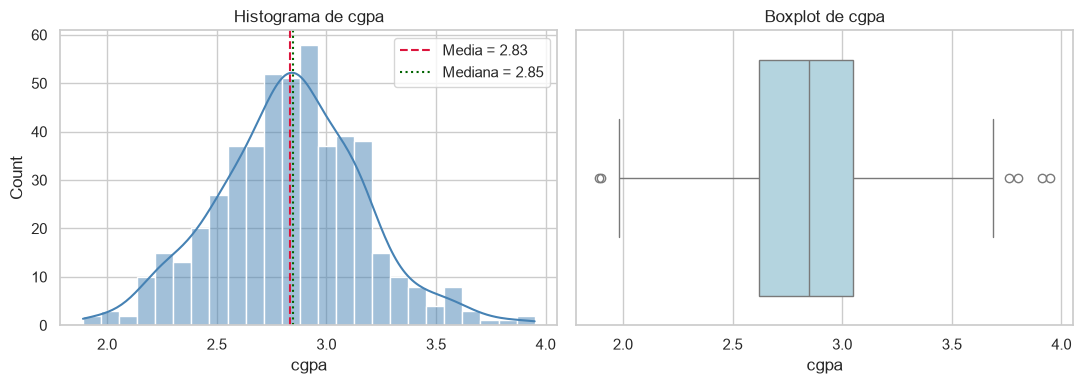

,cgpa
n (sin faltantes),493.00
faltantes,7.00
media,2.83
mediana,2.85
desvío estándar,0.33
mínimo,1.89
Q1 (25%),2.62
Q3 (75%),3.05
máximo,3.95
asimetría,0.09


In [25]:
y = df["cgpa"].dropna()

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(y, kde=True, bins=25, ax=ejes[0], color="steelblue")
ejes[0].axvline(y.mean(), color="crimson", ls="--", label=f"Media = {y.mean():.2f}")
ejes[0].axvline(y.median(), color="darkgreen", ls=":", label=f"Mediana = {y.median():.2f}")
ejes[0].set_title("Histograma de cgpa")
ejes[0].set_xlabel("cgpa")
ejes[0].legend()

sns.boxplot(x=y, ax=ejes[1], color="lightblue")
ejes[1].set_title("Boxplot de cgpa")
ejes[1].set_xlabel("cgpa")

plt.tight_layout()
plt.show()

resumen = pd.Series({
    "n (sin faltantes)": len(y),
    "faltantes": df["cgpa"].isna().sum(),
    "media": y.mean(),
    "mediana": y.median(),
    "desvío estándar": y.std(),
    "mínimo": y.min(),
    "Q1 (25%)": y.quantile(0.25),
    "Q3 (75%)": y.quantile(0.75),
    "máximo": y.max(),
    "asimetría": y.skew(),
}).round(2)

display(resumen.to_frame("cgpa"))

La variable objetivo `cgpa` tiene 493 observaciones válidas (7 faltantes), con una media de 2,83 y una mediana de 2,85. Al ser valores muy cercanos, la distribución es simétrica, lo que confirma la asimetría casi nula (0,09). El desvío estándar es de 0,33 y los valores van de 1,89 a 3,95, con la mitad central de los estudiantes entre 2,62 y 3,05.

El histograma muestra una forma de campana, similar a una distribución normal, y el boxplot muestra pocos valores alejados del resto. Esta forma regular de la variable respalda el uso de modelos de regresión lineal.

### Relplots

C:\Users\59899\.conda\envs\pcd\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
C:\Users\59899\.conda\envs\pcd\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


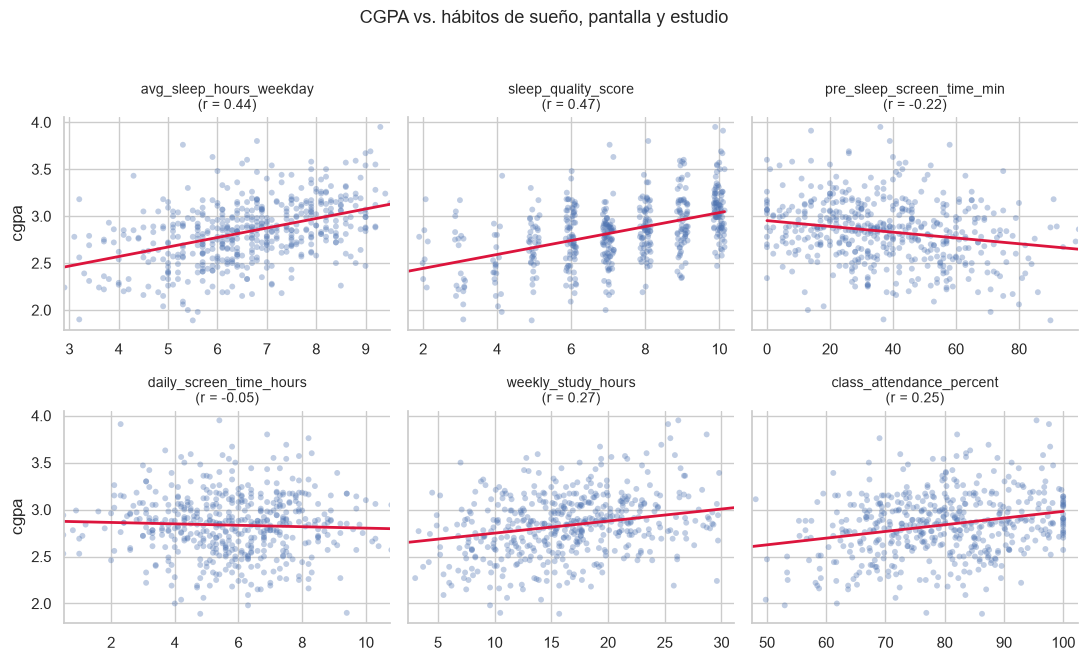

In [26]:
sns.set_theme(style="whitegrid")

vars_x = [
    "avg_sleep_hours_weekday",
    "sleep_quality_score",
    "pre_sleep_screen_time_min",
    "daily_screen_time_hours",
    "weekly_study_hours",
    "class_attendance_percent",
 ]

largo = df.melt(id_vars="cgpa", value_vars=vars_x,
                var_name="variable", value_name="valor").dropna()

rng = np.random.default_rng(1)
for v in vars_x:
    if df[v].nunique() <= 12:
        m = largo["variable"] == v
        largo.loc[m, "valor"] += rng.uniform(-0.15, 0.15, m.sum())

g = sns.lmplot(
    data=largo,
    x="valor",
    y="cgpa",
    col="variable",
    col_wrap=3,
    col_order=vars_x,
    height=3.2,
    aspect=1.15,
    ci=None,
    sharex=False,
    sharey=True,
    scatter_kws={"alpha": 0.35, "s": 18, "edgecolor": "none"},
    line_kws={"color": "crimson", "lw": 2},
)

for v, ax in g.axes_dict.items():
    r = df[v].corr(df["cgpa"])
    ax.set_title(f"{v}\n(r = {r:.2f})", fontsize=10)
    lo, hi = df[v].quantile([0.01, 0.99])
    margen = (hi - lo) * 0.05
    ax.set_xlim(lo - margen, hi + margen)

g.set_axis_labels("", "cgpa")
g.figure.suptitle("CGPA vs. hábitos de sueño, pantalla y estudio", y=1.03, fontsize=13)
g.figure.tight_layout()
plt.show()

Se observa que existen algunas correlaciones relativamente fuertes en las variables que representan horas de sueño y horas de estudio, podemos ver que a mayor cantidad de horas de sueño y de estudio, los estudiantes tienen mejor rendimiento. Por el contrario, cuanto mas horas de uso de pantalla tienen, menor es el rendimiento. Podemos observar algunos outliers que convendria eliminar para el posterior entrenamiento de un modelo.
Como cosas a resaltar, podemos ver que hay una gran cantidad de estudiantes que reportan uso de pantallas antes de dormir y que estas tienen un mayor impacto en el gpa que las horas de pantalla total diarias. Es decir, los datos sugieren que un estudiante que tiene 10 horas de uso de pantallas al dia, pero que las distribuye fuera del horario previo a dormir, tendria mejores notas que uno que usa mucho de ese tiempo antes de dormir.

C:\Users\59899\.conda\envs\pcd\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


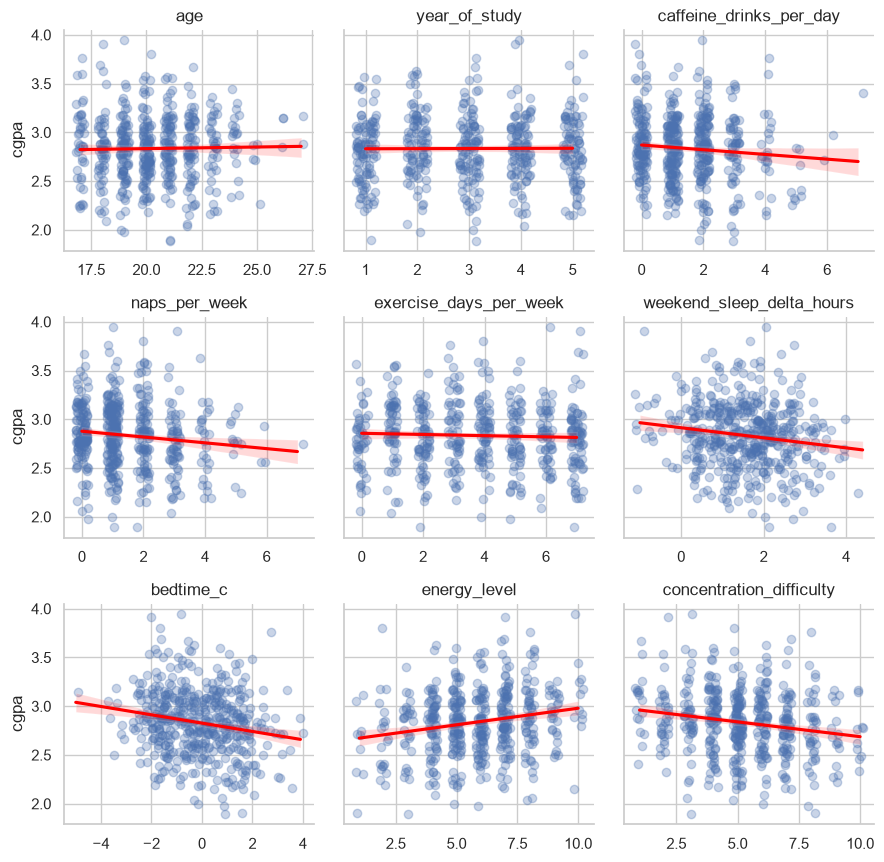

In [27]:

vars_menos = [
    "age",
    "year_of_study",
    "caffeine_drinks_per_day",
    "naps_per_week",
    "exercise_days_per_week",
    "weekend_sleep_delta_hours",
    "bedtime_c",
    "energy_level",
    "concentration_difficulty",
]

largo2 = df.melt(id_vars="cgpa", value_vars=vars_menos,
                 var_name="variable", value_name="valor")

g = sns.lmplot(
    data=largo2, x="valor", y="cgpa",
    col="variable", col_wrap=3, height=3,
    sharex=False, x_jitter=0.2,
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"},
)
g.set_titles("{col_name}")
g.set_axis_labels("", "cgpa")
plt.show()

Algunas de las variables que aqui observamos, a priori menos relevantes que las primeras, tienen una relacion con el desempeño academico. Por ejemplo, la cantidad de siestas semanales, la variacion de horas en un fin de semana con respecto a la semana y la hora de dormir con respecto a la medianoche tienen una correlacion lineal negativa. Es interesante observar que los estudiantes que duermen poco entre semana y luego en los fines de semana duermen mas (posiblemente saldando la deuda de sueño) tienen rendimientos menores que los que tienen patrones de sueño mas estables. Luego, tenemos que los estudiantes que se acuestan mas tarde tienen tambien rendimientos peores que los que se acuestan temprano.
También relacionado con el sueño, tenemos que los estudiantes que mas siestas durante la semana y los que mas cafeina consumen tienen rendimientos peores que los que no lo hacen tanto, la hipotesis aca sería que estos estudiantes que duermen muchas siestas y consumen mas cafeína tambien son de los que tienen patrones de sueño mas irregulares y duermen menos horas durante la semana.
Por otra parte, tenemos que los estudiantes que tienen un nivel de energia alto tienen mejor rendimiento que los que tienen uno bajo y los estudiantes que tienen menor dificiultad para concentrarse tienen un mejor desempeño academico que los que tienen mayor dificultad.

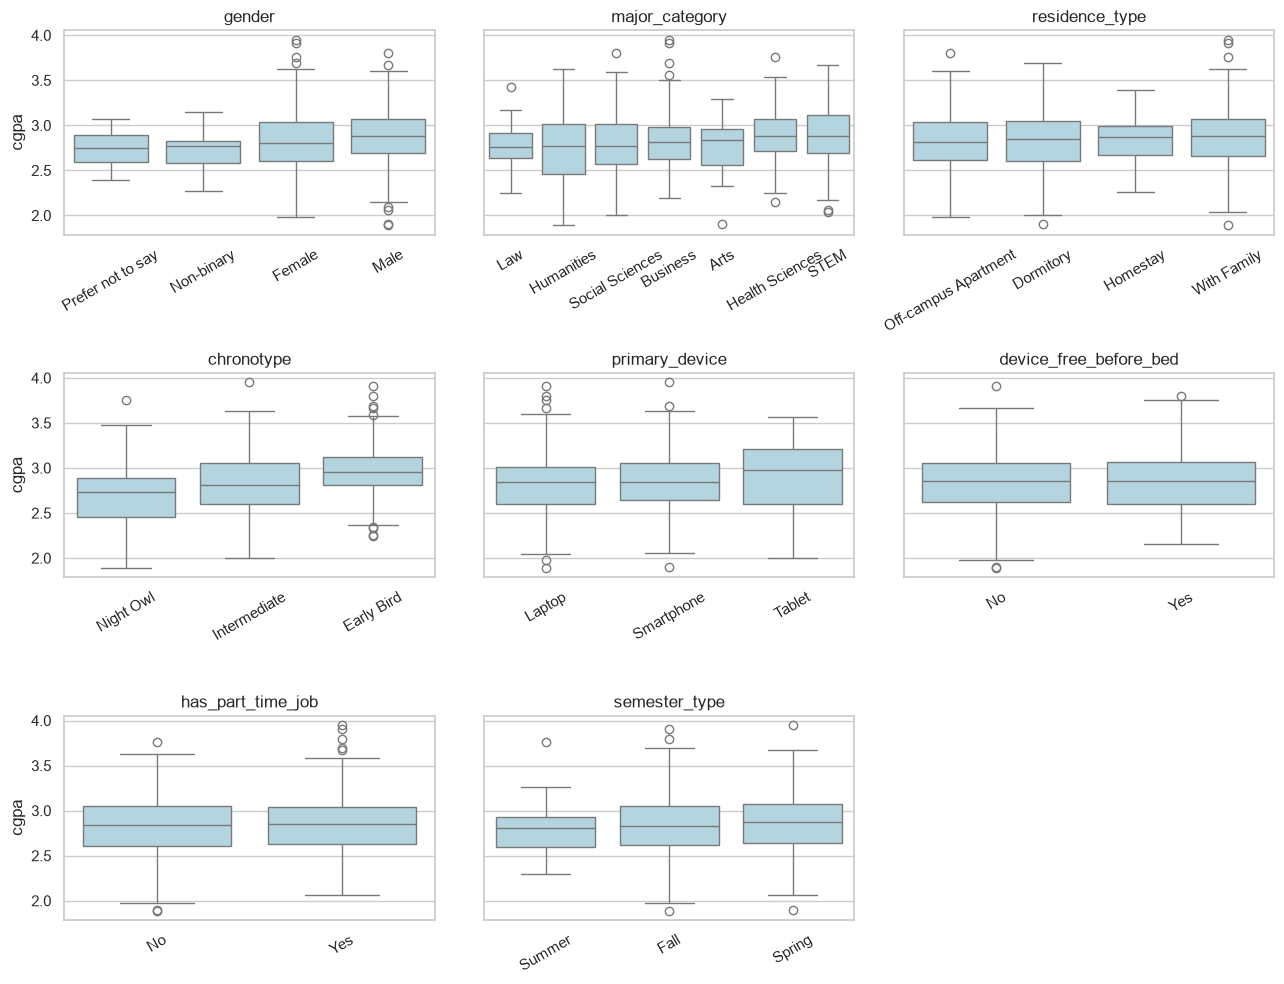

In [28]:
sns.set_theme(style="whitegrid")
vars_cat = ["gender", "major_category", "residence_type", "chronotype",
            "primary_device", "device_free_before_bed", "has_part_time_job", "semester_type"]

fig, ejes = plt.subplots(3, 3, figsize=(13, 10), sharey=True)
ejes = ejes.flatten()

for ax, v in zip(ejes, vars_cat):
    orden = df.groupby(v)["cgpa"].median().sort_values().index
    sns.boxplot(data=df, x=v, y="cgpa", order=orden, ax=ax, color="lightblue")
    ax.set_title(v)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

ejes[-1].axis("off")
plt.tight_layout()
plt.show()


Segun lo observado en estos graficos, no hay variables que tengan un mayor impacto en el gpa. A destacar, no hay una diferencia significativa entre estudiantes que no utilizan dispositivos antes de dormir con los que si utilizan. También podemos observar, que esta vinculado con lo que observamos en el analisis anterior, que los estudiantes que son "Early Birds" (se levantan temprano) tienen mejor rendimiento que las otras categorias. Por otro lado tenemos el trabajo de medio tiempo, que en contra de la intuición, nos muestra que los estudiantes que tienen un trabajo part time tienen resultados similares e incluso levemente superiores a los que no tienen.

### Heatmap

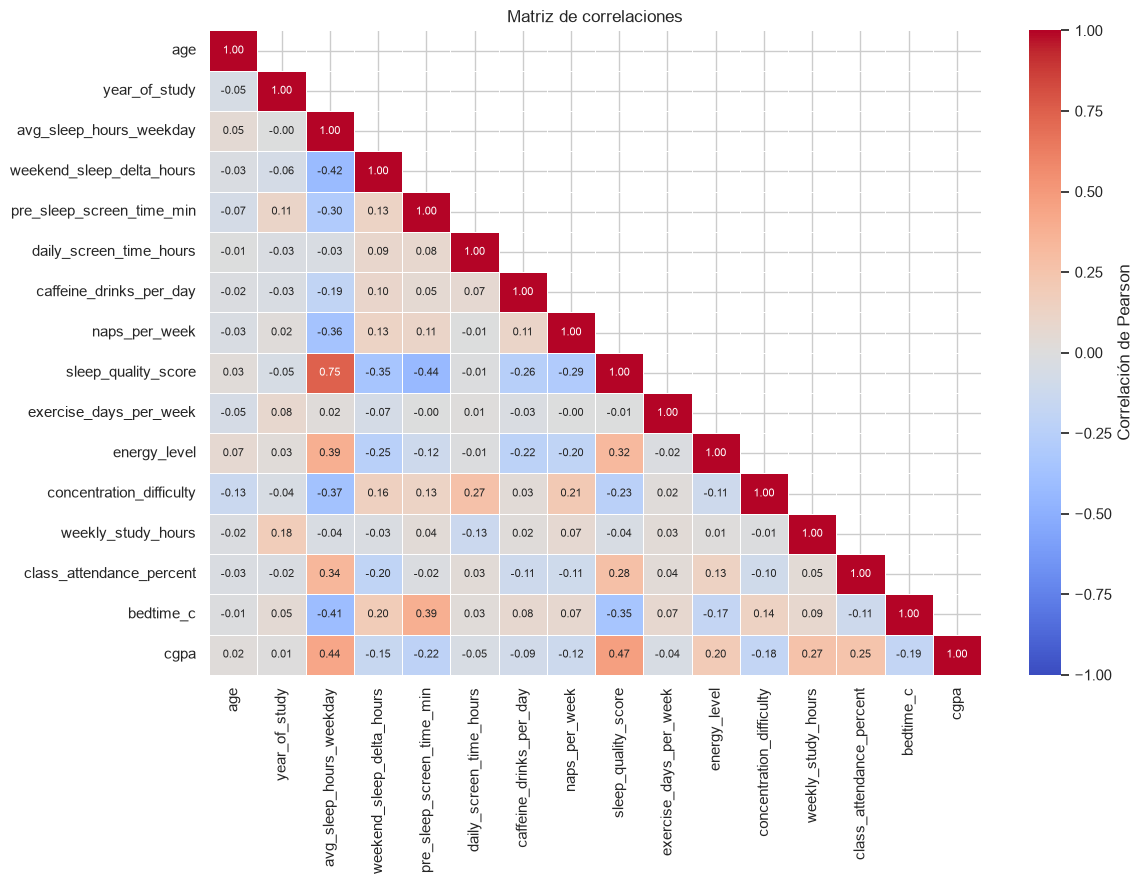

In [29]:
num = df.select_dtypes("number").drop(columns=["avg_bedtime_hour"])
num = num[[c for c in num.columns if c != "cgpa"] + ["cgpa"]]

corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={"label": "Correlación de Pearson"})
plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

El heatmap muestra que el sueño es el eje que organiza buena parte de los datos. Las dos variables más asociadas al rendimiento son la calidad del sueño (r = 0,47) y las horas de sueño entre semana (r = 0,44), mientras que las horas de estudio (0,27) y la asistencia a clase (0,25) tienen una asociación menor. Es decir, en este conjunto el sueño se asocia más con el cgpa que el esfuerzo académico declarado. Todas las correlaciones con cgpa son moderadas o débiles (ninguna supera 0,5), por lo que ninguna variable por sí sola explica gran parte del rendimiento.

Las variables relacionadas con el sueño además forman un grupo con correlaciones cruzadas: quienes duermen menos entre semana tienden a acostarse más tarde (-0,41), a compensar más el fin de semana (-0,42), a hacer más siestas (-0,36), a consumir más cafeína (-0,19), a tener más dificultad para concentrarse (-0,37) y menos energía (0,39). Esto sugiere que muchas de las asociaciones débiles que se observan con cgpa (siestas, cafeína, diferencia de fin de semana, hora de acostarse) no son efectos independientes, sino reflejo de un mismo patrón de sueño insuficiente o irregular.

El uso de pantallas muestra un comportamiento diferenciado. Las horas totales de pantalla casi no se relacionan con cgpa (-0,05), pero el tiempo de pantalla justo antes de dormir sí (-0,22) y se asocia con peor calidad del sueño (-0,44), con acostarse más tarde (0,39) y con dormir menos horas (-0,30). Esto es coherente con lo que observamos anteriormente, las siestas y el consumo de cafeina podrian indicar un comportamiento de compensacion de una mala calidad de sueño

Por último, la correlación entre horas de sueño entre semana y calidad del sueño es muy alta (0,75), la mayor de toda la matriz, aunque no nos aporta mucha información relevante, ya que tiene todo el sentido del mundo que una buena calidad de sueño este estrechamente relacionada con la cantidad de horas de sueño.

## 4 - Modelado

Edicion de los datos

In [30]:
num = ["age", "year_of_study", "avg_sleep_hours_weekday", "sleep_quality_score", "bedtime_c",
       "weekend_sleep_delta_hours", "pre_sleep_screen_time_min", "daily_screen_time_hours",
       "caffeine_drinks_per_day", "naps_per_week", "exercise_days_per_week",
       "weekly_study_hours", "class_attendance_percent"]
cat = ["gender", "major_category", "residence_type", "chronotype", "primary_device",
       "device_free_before_bed", "has_part_time_job", "semester_type"]

d = df[["cgpa"] + num + cat].dropna()
d = d[d["class_attendance_percent"] <= 100] #Borramos Aquellos datos de personas con mas de 100% de asistencia
n_antes = len(d)
d = d[d["weekly_study_hours"] <= 60] #Borramos a una persona que tenía mas de 88 horas de estudio semanales
print(f"Se eliminaron {n_antes - len(d)} fila(s)")

print(d.shape)
d[num].describe().T[["min", "max"]]

Se eliminaron 1 fila(s)
(477, 22)


,min,max
age,17.0,27.0
year_of_study,1.0,5.0
avg_sleep_hours_weekday,1.5,10.5
sleep_quality_score,1.0,10.0
bedtime_c,-5.0,3.9
weekend_sleep_delta_hours,-1.0,4.4
pre_sleep_screen_time_min,0.0,240.0
daily_screen_time_hours,0.5,19.5
caffeine_drinks_per_day,0.0,7.0
naps_per_week,0.0,7.0


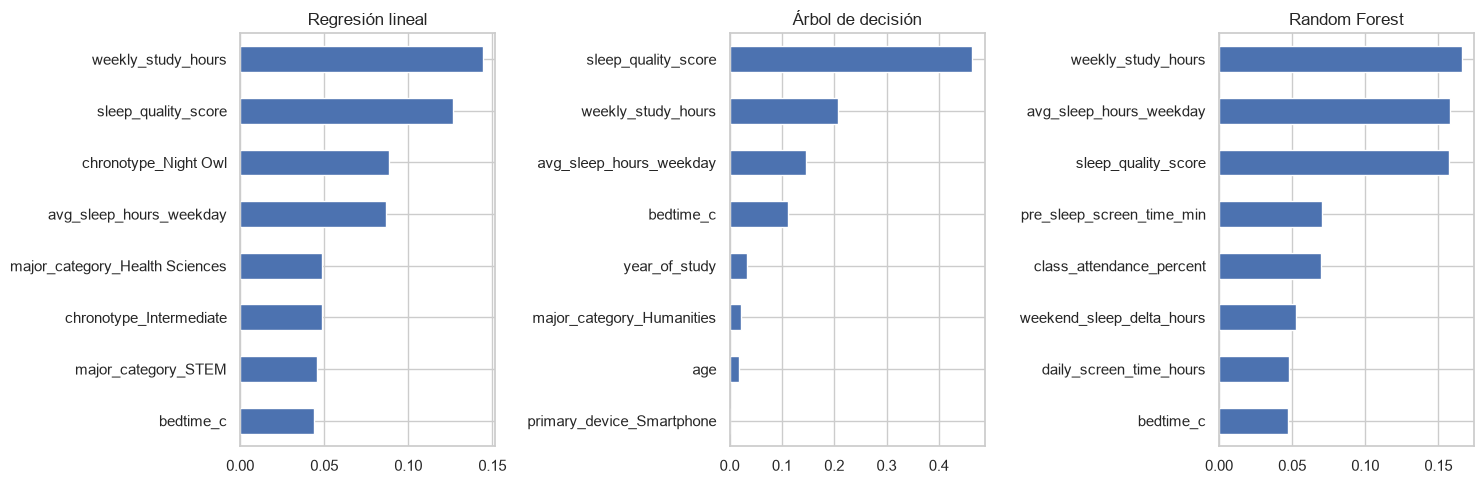

,Modelo,R2,RMSE,MAE
0,Regresión lineal,0.286,0.265,0.214
1,Árbol de decisión,0.089,0.299,0.233
2,Random Forest,0.279,0.266,0.211


In [31]:
X = pd.get_dummies(d[num + cat], drop_first=True, dtype=float)
y = d["cgpa"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=1)

modelos = {
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=4, random_state=1),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=1),
}

filas = []
for nombre, modelo in modelos.items():
    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_te)
    filas.append([nombre,
                  r2_score(y_te, pred),
                  mean_squared_error(y_te, pred) ** 0.5,
                  mean_absolute_error(y_te, pred)])

imp = pd.DataFrame({
    "Regresión lineal": (pd.Series(modelos["Regresión lineal"].coef_, index=X.columns) * X_tr.std()).abs(),
    "Árbol de decisión": modelos["Árbol de decisión"].feature_importances_,
    "Random Forest": modelos["Random Forest"].feature_importances_,
}, index=X.columns)
imp = imp / imp.sum()

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(ejes, imp.columns):
    imp[col].sort_values().tail(8).plot.barh(ax=ax, title=col)
plt.tight_layout()
plt.show()

pd.DataFrame(filas, columns=["Modelo", "R2", "RMSE", "MAE"]).round(3)

El modelo de regresión lineal y el Random Forest obtuvieron desempeños similares, mientras que el Arbol de Decisión tuvo un mal rendimiento en el R2. Que el Random Forest no supere a la regresión lineal sugiere que la relación es principalmente lineal, por lo que la regresión lineal es la mejor opción por ser la más simple e interpretable.
Las tres variables que más pesan en los modelos son "weekly_study_hours", "sleep_quality_score" y "avg_sleep_hours_weekday". Las dos primeras aparecen entre las tres más importantes en los tres modelos, y las horas de sueño en días de semana también están en los tres. Esto sugiere que el estudio y el sueño son los hábitos más asociados con una nota alta.
Tambien aparecen otras variables menos importantes pero que los 3 mdoelos tomaron en cuenta como "bedtime_c" (hora de acostarse) que esytá en los tres modelos con una importancia menor. Mientras que el tiempo de pantalla antes de dormir y la asistencia a clase (que esperabamos muy importantes) destacan solo en el Random Forest.
La importancia indica cuánto usa cada modelo una variable para predecir.

Como Ultimo Paso decidimos crear una herramienta para el usuario en donde el mismo utilizará su propios habitos y serán comparado con los estudiantes de la base de datos para estimar en que percentil, que nota y cuan mejor que el promedio es.

In [32]:
# Nuevo Modelo de regresión con variables de hábitos
clave = ["weekly_study_hours", "sleep_quality_score", "avg_sleep_hours_weekday",
         "bedtime_c", "pre_sleep_screen_time_min", "class_attendance_percent"]

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(d[clave], d["cgpa"], test_size=0.2, random_state=1)
modelo_final = LinearRegression().fit(Xc_tr, yc_tr)
rmse = mean_squared_error(yc_te, modelo_final.predict(Xc_te)) ** 0.5

def predecir(**habitos):
    fila = pd.DataFrame([habitos])[clave]
    pred = modelo_final.predict(fila)[0]
    return min(max(pred, d["cgpa"].min()), d["cgpa"].max())

tipico = d[clave].mean().to_dict()
base = predecir(**tipico)
pred_base = modelo_final.predict(d[clave])

In [33]:
import ipywidgets as widgets
from ipywidgets import FloatSlider, VBox, Layout, interactive_output
from IPython.display import HTML, display

def percentil(cgpa):
    return (pred_base < cgpa).mean() * 100

def a_concepto(cgpa):
    p = percentil(cgpa)
    for corte, nombre in [(90, "Excelente"), (70, "Muy bueno"), (40, "Bueno"),
                          (15, "Aceptable"), (5, "Insuficiente")]:
        if p >= corte:
            return nombre
    return "Muy insuficiente"

colores = {"Excelente": "#2e7d32", "Muy bueno": "#7cb342", "Bueno": "#f9a825",
           "Aceptable": "#fb8c00", "Insuficiente": "#e53935", "Muy insuficiente": "#b71c1c"}

def herramienta(**habitos):
    est = predecir(**habitos)
    c = a_concepto(est)
    display(HTML(f"""
    <div style='border-left:10px solid {colores[c]}; background:#f5f5f5; color:#222;
                padding:14px 20px; border-radius:8px; width:580px; font-size:15px; line-height:1.6'>
      <div style='font-size:30px; font-weight:bold; color:{colores[c]}'>{c}</div>
      cgpa estimado: <b>{est:.2f}</b> (mejor que el {percentil(est):.0f}% de la base)<br>
      Rango probable: {a_concepto(est - rmse)} a {a_concepto(est + rmse)}<br>
      Frente al estudiante típico: <b>{est - base:+.2f}</b> puntos de cgpa
    </div>"""))

config = {
    "weekly_study_hours":        ("Horas de estudio por semana", 0.5),
    "sleep_quality_score":       ("Calidad del sueño (1-10)", 1),
    "avg_sleep_hours_weekday":   ("Horas de sueño entre semana", 0.25),
    "bedtime_c":                 ("Hora de acostarse (0 = medianoche)", 0.25),
    "pre_sleep_screen_time_min": ("Minutos de pantalla antes de dormir", 5),
    "class_attendance_percent":  ("Asistencia a clase (%)", 1),
}

sliders = {v: FloatSlider(value=round(d[v].mean(), 1), min=round(d[v].quantile(0.01), 1),
                          max=round(d[v].quantile(0.99), 1), step=paso, description=nombre,
                          continuous_update=False, readout_format=".1f",
                          layout=Layout(width="700px"),
                          style={"description_width": "300px", "handle_color": "#034383"})
           for v, (nombre, paso) in config.items()}

titulo = widgets.HTML("<h3 style='margin:0'>Estimador de cgpa según hábitos</h3>"
                      "<span style='color:gray'>Mové los controles y soltá para ver el resultado</span>")
caja = VBox(list(sliders.values()), layout=Layout(border="1px solid #4c4b4b", padding="14px", width="780px"))

display(VBox([titulo, caja, interactive_output(herramienta, sliders)]))